# Omnifold Exercise #

##### Import relevant libaries #####

In [ ]:
import tensorflow as tf
import time

import numpy as np
import matplotlib.pyplot as plt

In [ ]:
gpus = tf.config.list_physical_devices("GPU")
device = "GPU" if gpus else "CPU"

print(device)

GPU


OmniFold: A Method to Simultaneously Unfold All Observables <br> *Anders Andreassen, Patrick T. Komiske, Eric M. Metodiev, Benjamin Nachman and Jesse Thaler*<br>https://arxiv.org/pdf/1911.09107

We are going to work with a dataset from https://zenodo.org/records/3548091. In particular, we will be looking into three jet-substructure observables of the leading jet, the jet width, the soft-drop mass and the $N_{12}$-subjetiness ratio. The goal is to unfold detector effects and infer $p_\text{data} (x_\text{reco}) \rightarrow p_\text{unfold} (x_\text{part})$ of the 3-dimensional phase space.

Load data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd /content/drive/Shareddrives/Statistics\ and\ Data\ Analysis/Lectures/DL lectures/Lecture 20/Exercises/omnifold_data/
!ls

/content/drive/Shareddrives/Statistics and Data Analysis/Lectures/DL lectures/Lecture 20/Exercises/omnifold_data
part_data.npy  part_MC.npy  reco_data.npy  reco_MC.npy


In [ ]:
reco_sim = np.load("reco_MC.npy").astype(np.float32)
reco_data = np.load("reco_data.npy").astype(np.float32)
part_sim = np.load("part_MC.npy").astype(np.float32)
part_data = np.load("part_data.npy").astype(np.float32)

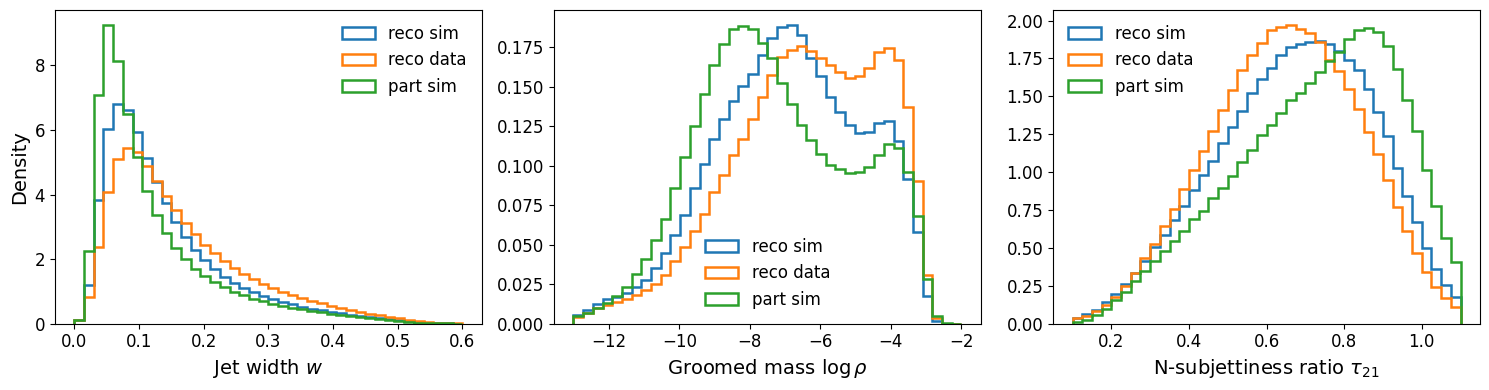

In [ ]:
FONTSIZE = 14

n_features = reco_sim.shape[1]

binning = [np.linspace(0, 0.6, 40 + 1),
           np.linspace(-13, -2, 40 + 1),
           np.linspace(0.1, 1.1, 40 + 1)]

names = [r"\text{Jet width } w",
         r"\text{Groomed mass }\log \rho",
         r"\text{N-subjettiness ratio } \tau_{21}"]

fig, axes = plt.subplots(1, n_features, figsize=(5 * n_features, 4), sharey=False)

for i in range(n_features):
    ax = axes[i] if n_features > 1 else axes

    ax.hist(reco_sim[:, i], bins=binning[i], density=True, histtype="step", linewidth=1.8, label="reco sim")
    ax.hist(reco_data[:, i], bins=binning[i], density=True, histtype="step", linewidth=1.8, label="reco data")
    ax.hist(part_sim[:, i], bins=binning[i], density=True, histtype="step", linewidth=1.8, label="part sim")

    ax.set_xlabel(rf"${names[i]}$", fontsize=FONTSIZE)
    if i == 0:
        ax.set_ylabel("Density", fontsize=FONTSIZE)
    ax.tick_params(labelsize=FONTSIZE - 2)
    ax.legend(frameon=False, fontsize=FONTSIZE - 2)

plt.tight_layout()
plt.show()

Build training and test datasets if needed

In [ ]:
reco_sim_train, reco_sim_test = reco_sim[:750000], reco_sim[750000:]
reco_data_train, reco_data_test = reco_data[:750000], reco_data[750000:]
part_sim_train, part_sim_test = part_sim[:750000], part_sim[750000:]

We will define some preprocessing functions to apply to the data.

In [ ]:
mean = np.array([0.1411, -6.9493, 0.6731], dtype=np.float32)
std = np.array([0.0960, 2.2009, 0.2031], dtype=np.float32)

In [ ]:
def preprocess(data, mean, std, reverse=False):
    """
    Standardizes or un-standardizes NumPy arrays.

    Args:
        data (array-like): Input data.
        mean (array-like or float): Mean used for standardization.
        std (array-like or float): Standard deviation used for standardization.
        reverse (bool): If True, reverses the standardization.

    Returns:
        np.ndarray: Processed data array.
    """
    data = np.asarray(data, dtype=np.float32)
    mean = np.asarray(mean, dtype=np.float32)
    std = np.asarray(std, dtype=np.float32)
    if not reverse:
        return (data - mean) / std
    return (data * std) + mean


In [ ]:
# Copy and preprocess the data to standardize input features with reco-level MC mean and standard deviation.

reco_sim_proc_train = preprocess(reco_sim_train.copy(), mean, std)
reco_sim_proc_test = preprocess(reco_sim_test.copy(), mean, std)

reco_data_proc_train = preprocess(reco_data_train.copy(), mean, std)

part_sim_proc_train = preprocess(part_sim_train.copy(), mean, std)
part_sim_proc_test = preprocess(part_sim_test.copy(), mean, std)

### Exercise 1 - Building a Classifier in TensorFlow/Keras

In this first exercise, implement a flexible binary classifier using TensorFlow/Keras, which will then serve as a core component in the OmniFold algorithm.

The aim is to build a reusable classifier class or a set of functions. A modular design allows us to train and evaluate the classifier multiple times throughout the unfolding process.


In [ ]:
# code here...

### Exercise 2 - Single Iteration Omnifold

To get a better understanding of omnifold we will start by doing the first iteration explicitly. For one iteration implement the following steps:

1. Train a classifier between $p_{\text{sim}}(x_{\text{reco}})$ and $p_{\text{data}}(x_{\text{reco}})$

In [ ]:
# code here...

2. Evaluate $w_\theta(x_\text{reco})$ with $x_\text{reco} \sim p_{\text{sim}}(x_{\text{reco}})$

In [ ]:
# code here...

3. Plot $p_\text{sim}(x_\text{reco})$, $p_{\text{data}}(x_{\text{reco}})$ and $w_\theta(x_\text{reco})p_\text{sim}(x_\text{reco})$

In [ ]:
# code here...

4. Pull the reco-level event to particle-level $w_\theta(x_\text{reco}) \rightarrow w_\theta(x_\text{part})$ using the pairing in simulation
   
5. Plot $p_\text{sim}(x_\text{part})$, $p_{\text{data}}(x_{\text{part}})$ and $w_\theta(x_\text{part})p_\text{sim}(x_\text{part})$

In [ ]:
# code here...

##### What do you observe?

6. Train a classifier between $p_{\text{sim}}(x_{\text{part}})$ and $w_\theta (x_\text{part}) p_{\text{sim}}(x_{\text{part}})$

In [ ]:
# code here...

7. Evaluate $\nu_\phi (x_\text{part})$ with $x_\text{part} \sim p_\text{sim}(x_\text{part})$

In [ ]:
# code here...

8. Plot $p_\text{sim}(x_\text{part})$, $p_{\text{data}}(x_{\text{part}})$ and $\nu_\phi(x_\text{part})p_\text{sim}(x_\text{part})$

In [ ]:
# code here...

9. Push the particle-level event to reco-level $\nu_\phi(x_\text{part}) \rightarrow \nu_\phi(x_\text{reco})$ using the pairing in simulation

10. Plot $p_\text{sim}(x_\text{reco})$, $p_{\text{data}}(x_{\text{reco}})$ and $\nu_\phi(x_\text{reco})p_\text{sim}(x_\text{reco})$

In [ ]:
# code here...

##### What do you observe?

### Exercise 3 - Iterative Omnifold

Now that we have walked through a single iteration of OmniFold step-by-step, it's time to automate the full iterative unfolding procedure.
Add all indivual steps to an iterative loop.

In [ ]:
iterations = 3

# code here...